In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas :", pd.__version__)
print("Matplotlib :", plt.matplotlib.__version__)
print("Seaborn :", sns.__version__)

Pandas : 2.3.1
Matplotlib : 3.10.3
Seaborn : 0.13.2


Importation du dataset nettoyé

In [2]:

df = pd.read_csv("data/clean/data_clean.csv")

# Afficher les 5 premières lignes
df.head()

,Store,Date,DayOfWeek,Sales,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,528,2013-06-08,6,3812,0,0,0,c,a,67578.758628,10,2011,1,29,2013,"Mar,Jun,Sept,Dec"
1,60,2013-09-24,2,6829,0,0,0,c,c,39604.358671,7,2008,0,0,0,Aucun
2,878,2014-07-01,2,6488,0,0,1,c,c,68892.844012,7,2011,0,0,0,Aucun
3,371,2013-03-29,5,4501,0,0,0,a,a,28895.722759,9,2013,0,0,0,Aucun
4,306,2013-05-26,7,10118,1,0,0,a,b,51879.787383,4,2002,0,0,0,Aucun


Afficher le nombre de lignes et de colonnes

In [4]:
df.shape

(803252, 16)

Afficher les informations générales du dataset

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 803252 entries, 0 to 803251
Data columns (total 16 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   Store                      803252 non-null  int64  
 1   Date                       803252 non-null  object 
 2   DayOfWeek                  803252 non-null  int64  
 3   Sales                      803252 non-null  int64  
 4   Promo                      803252 non-null  int64  
 5   StateHoliday               803252 non-null  object 
 6   SchoolHoliday              803252 non-null  int64  
 7   StoreType                  803252 non-null  object 
 8   Assortment                 803252 non-null  object 
 9   CompetitionDistance        803252 non-null  float64
 10  CompetitionOpenSinceMonth  803252 non-null  int64  
 11  CompetitionOpenSinceYear   803252 non-null  int64  
 12  Promo2                     803252 non-null  int64  
 13  Promo2SinceWeek            80

In [6]:
df.describe()

,Store,DayOfWeek,Sales,Promo,SchoolHoliday,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear
count,803252.000000,803252.000000,803252.000000,803252.000000,803252.000000,803252.000000,803252.000000,803252.000000,803252.000000,803252.000000,803252.000000
mean,558.006329,3.997109,6205.436570,0.380188,0.213137,37569.793330,5.549876,1713.653988,0.370439,9.236008,745.364802
std,321.889990,1.999964,3045.381611,0.485433,0.409524,21109.264613,3.904387,709.047131,0.482923,14.977577,971.694843
min,1.000000,1.000000,0.000000,0.000000,0.000000,27.601853,0.000000,0.000000,0.000000,0.000000,0.000000
25%,279.000000,2.000000,4524.000000,0.000000,0.000000,19726.622898,2.000000,2001.000000,0.000000,0.000000,0.000000
50%,558.000000,4.000000,6334.000000,0.000000,0.000000,37583.381105,6.000000,2006.000000,0.000000,0.000000,0.000000
75%,837.000000,6.000000,8144.000000,1.000000,0.000000,55220.873569,9.000000,2010.000000,1.000000,16.000000,2011.000000
max,1115.000000,7.000000,21387.000000,1.000000,1.000000,74973.315260,12.000000,2014.000000,1.000000,52.000000,2015.000000


 Afficher les catégories uniques des variables catégorielles

In [ ]:
print("Catégories de StateHoliday :")
print(df["StateHoliday"].unique())

print("\nCatégories de StoreType :")
print(df["StoreType"].unique())

print("\nCatégories de Assortment :")
print(df["Assortment"].unique())

print("\nCatégories de PromoInterval :")
print(df["PromoInterval"].unique())

Catégories de StateHoliday :
['0' 'b' 'a' 'c']

Catégories de StoreType :
['c' 'a' 'b' 'd']

Catégories de Assortment :
['a' 'c' 'b']

Catégories de PromoInterval :
['Mar,Jun,Sept,Dec' 'Aucun' 'Feb,May,Aug,Nov' 'Jan,Apr,Jul,Oct']



 Compter les occurrences de chaque catégorie

In [8]:

print("Répartition des types de magasins :")
print(df["StoreType"].value_counts())

print("\nRépartition des assortiments :")
print(df["Assortment"].value_counts())

print("\nRépartition des jours fériés :")
print(df["StateHoliday"].value_counts())

print("\nRépartition des intervalles promotionnels :")
print(df["PromoInterval"].value_counts())

Répartition des types de magasins :
StoreType
a    329234
b    202427
c    201706
d     69885
Name: count, dtype: int64

Répartition des assortiments :
Assortment
a    404901
c    327759
b     70592
Name: count, dtype: int64

Répartition des jours fériés :
StateHoliday
0    792028
a      6192
b      3931
c      1101
Name: count, dtype: int64

Répartition des intervalles promotionnels :
PromoInterval
Aucun               505696
Jan,Apr,Jul,Oct     103745
Feb,May,Aug,Nov      99432
Mar,Jun,Sept,Dec     94379
Name: count, dtype: int64


In [9]:
# Afficher toutes les catégories sans troncature
print(df["PromoInterval"].value_counts().to_string())

PromoInterval
Aucun               505696
Jan,Apr,Jul,Oct     103745
Feb,May,Aug,Nov      99432
Mar,Jun,Sept,Dec     94379


Visualiser la distribution du chiffre d'affaires

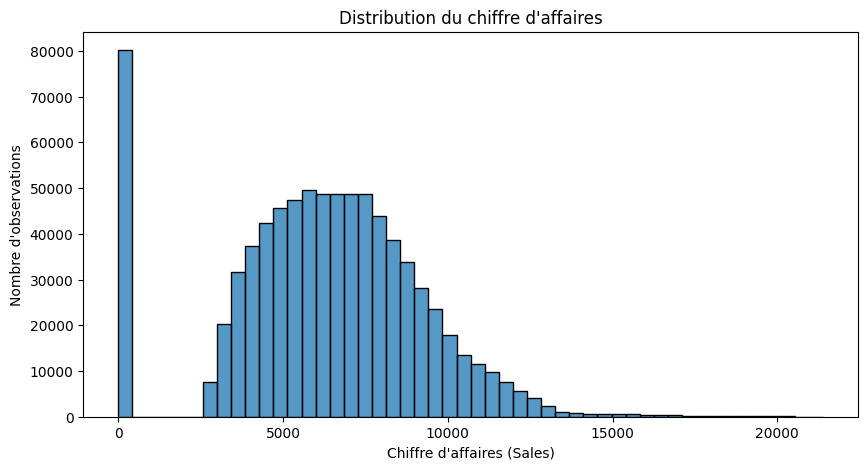

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Sales", bins=50)

plt.title("Distribution du chiffre d'affaires")
plt.xlabel("Chiffre d'affaires (Sales)")
plt.ylabel("Nombre d'observations")

plt.show()

In [11]:
# Calculer quelques indicateurs sur la distribution des ventes

print("Vente minimale :", df["Sales"].min())
print("Vente maximale :", df["Sales"].max())
print("Vente moyenne :", round(df["Sales"].mean(), 2))
print("Vente médiane :", df["Sales"].median())
print("Nombre de ventes nulles :", (df["Sales"] == 0).sum())

Vente minimale : 0
Vente maximale : 21387
Vente moyenne : 6205.44
Vente médiane : 6334.0
Nombre de ventes nulles : 80190


Calculer le pourcentage de ventes nulles

In [12]:
pourcentage_ventes_nulles = (df["Sales"].eq(0).sum() / len(df)) * 100

print("Pourcentage de ventes nulles :", round(pourcentage_ventes_nulles, 2), "%")

Pourcentage de ventes nulles : 9.98 %


Calculer l'asymétrie de la distribution des ventes

In [14]:
asymetrie = df["Sales"].skew()

print("Coefficient d'asymétrie :", round(asymetrie, 3))

Coefficient d'asymétrie : -0.159


Interprétation de la distribution du chiffre d'affaires

L'analyse de la variable `Sales` montre que :

- Le chiffre d'affaires moyen est de 6 205,44.
- La médiane est de 6 334.
- Les ventes varient entre 0 et 21 387.
- Environ 9,98 % des observations présentent un chiffre d'affaires nul.
- Le coefficient d'asymétrie est de -0,159, ce qui indique une légère asymétrie vers la gauche.

Ces résultats montrent que les ventes présentent une certaine dispersion. Les observations avec un chiffre d'affaires nul méritent une attention particulière, car le dataset ne permet pas de déterminer directement si les magasins étaient fermés.



Visualiser la dispersion des ventes avec un boxplot

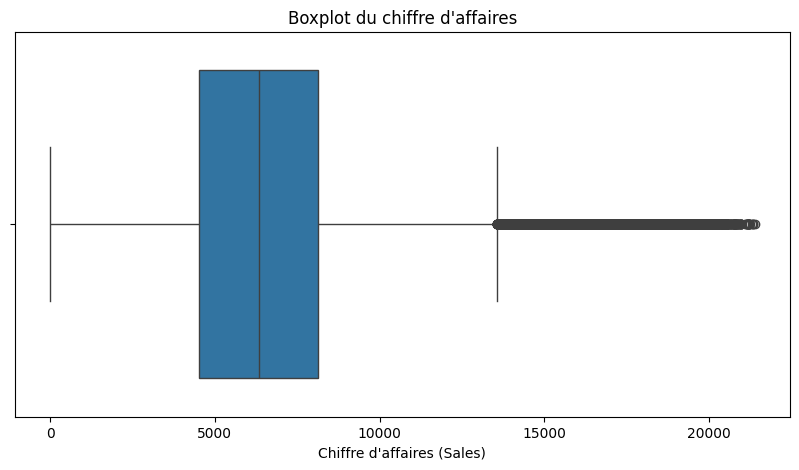

In [15]:

plt.figure(figsize=(10, 5))

sns.boxplot(x=df["Sales"])

plt.title("Boxplot du chiffre d'affaires")
plt.xlabel("Chiffre d'affaires (Sales)")

plt.show()

In [16]:
# Calcul des quartiles
Q1 = df["Sales"].quantile(0.25)
Q2 = df["Sales"].quantile(0.50)
Q3 = df["Sales"].quantile(0.75)

# Calcul de l'écart interquartile
IQR = Q3 - Q1

# Calcul des limites des valeurs extrêmes
limite_basse = Q1 - 1.5 * IQR
limite_haute = Q3 + 1.5 * IQR

# Affichage des résultats
print("Premier quartile (Q1) :", Q1)
print("Médiane (Q2) :", Q2)
print("Troisième quartile (Q3) :", Q3)
print("Écart interquartile (IQR) :", IQR)
print("Limite basse :", limite_basse)
print("Limite haute :", limite_haute)

# Nombre de valeurs extrêmes
outliers = df[
    (df["Sales"] < limite_basse) |
    (df["Sales"] > limite_haute)
]

print("Nombre de valeurs extrêmes :", len(outliers))

Premier quartile (Q1) : 4524.0
Médiane (Q2) : 6334.0
Troisième quartile (Q3) : 8144.0
Écart interquartile (IQR) : 3620.0
Limite basse : -906.0
Limite haute : 13574.0
Nombre de valeurs extrêmes : 5584


Première observation : 50 % des observations ont un chiffre d'affaires compris entre 4 524 et 8 144.

Deuxième observation : la limite basse est négative (-906), alors que notre chiffre d'affaires minimum est zéro. Il n'y a donc aucune valeur extrême inférieure selon cette règle.

Troisième observation : 5 584 observations dépassent la limite haute de 13 574. Elles représentent des ventes particulièrement élevées.

Calculer le pourcentage de valeurs extrêmes

In [17]:
pourcentage_outliers = (len(outliers) / len(df)) * 100

print("Pourcentage de valeurs extrêmes :", round(pourcentage_outliers, 2), "%")

Pourcentage de valeurs extrêmes : 0.7 %


Interprétation du boxplot de Sales

L'analyse du boxplot montre que :

- Le premier quartile (Q1) est de 4 524.
- La médiane est de 6 334.
- Le troisième quartile (Q3) est de 8 144.
- La moitié centrale des observations présente des ventes comprises entre 4 524 et 8 144.
- La limite supérieure de détection des valeurs extrêmes est de 13 574.
- 5 584 observations, soit environ 0,70 % du dataset, sont considérées comme des valeurs extrêmes.

Ces valeurs extrêmes correspondent à des journées où les ventes sont particulièrement élevées. Elles ne doivent pas être supprimées automatiquement, car elles peuvent représenter une activité commerciale réelle.

Nous les conserverons dans cette phase d'analyse et nous tiendrons compte de leur présence lors de la préparation des modèles prédictifs.

In [18]:
# Convertir la colonne Date au format datetime

df["Date"] = pd.to_datetime(df["Date"])

# Vérifier le type de la colonne
print(df["Date"].dtype)

datetime64[ns]


In [19]:
# Vérifier la période couverte par le dataset

print("Première date :", df["Date"].min())
print("Dernière date :", df["Date"].max())

Première date : 2013-01-01 00:00:00
Dernière date : 2014-12-23 00:00:00


In [20]:
# Regrouper les ventes de tous les magasins par date

ventes_journalieres = (
    df.groupby("Date")["Sales"]
    .sum()
    .reset_index()
)

# Afficher les 5 premières dates
print(ventes_journalieres.head())

        Date    Sales
0 2013-01-01  7461855
1 2013-01-02  7489714
2 2013-01-03  7435856
3 2013-01-04  7529890
4 2013-01-05  7505941


In [21]:
# Compter le nombre de dates disponibles

print("Nombre de dates :", len(ventes_journalieres))

Nombre de dates : 722
